# Homepage examples

The code and saved outputs used on the Bambi homepage.

In [1]:
import arviz as az
import bambi as bmb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Sleepstudy

A hierarchical linear model estimates how reaction time changes with days of sleep deprivation, allowing each subject to have their own intercept and slope.

In [2]:
data = bmb.load_data("sleepstudy")
data["Days"] = data["Days"].astype(float)

model = bmb.Model("Reaction ~ Days + (Days | Subject)", data, categorical="Subject")
idata = model.fit(random_seed=1211, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, Days, 1|Subject_sigma, 1|Subject_offset, Days|Subject_sigma, Days|Subject_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 3 seconds.


In [3]:
az.summary(
    idata,
    var_names=["Intercept", "Days", "1|Subject_sigma", "Days|Subject_sigma", "sigma"],
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Intercept,251.5,7.4,240,260,2978,2878,1.00,0.14,0.13
Days,10.46,1.74,7.7,13,1607,1747,1.00,0.044,0.031
1|Subject_sigma,27,6.5,18,38,1849,2263,1.00,0.15,0.15
Days|Subject_sigma,6.46,1.39,4.6,8.9,1895,2488,1.00,0.032,0.028
sigma,25.84,1.52,24,28,3869,2670,1.00,0.025,0.026


/tmp/ipykernel_58354/2909881105.py:2: PlottingFutureWarning: Bambi's interpret plotting functions currently return seaborn.objects.Plot objects. In a future version, they will return matplotlib.figure.Figure objects instead. To suppress this warning, use warnings.filterwarnings('ignore', category=bambi.PlottingFutureWarning).
  bmb.interpret.plot_predictions(


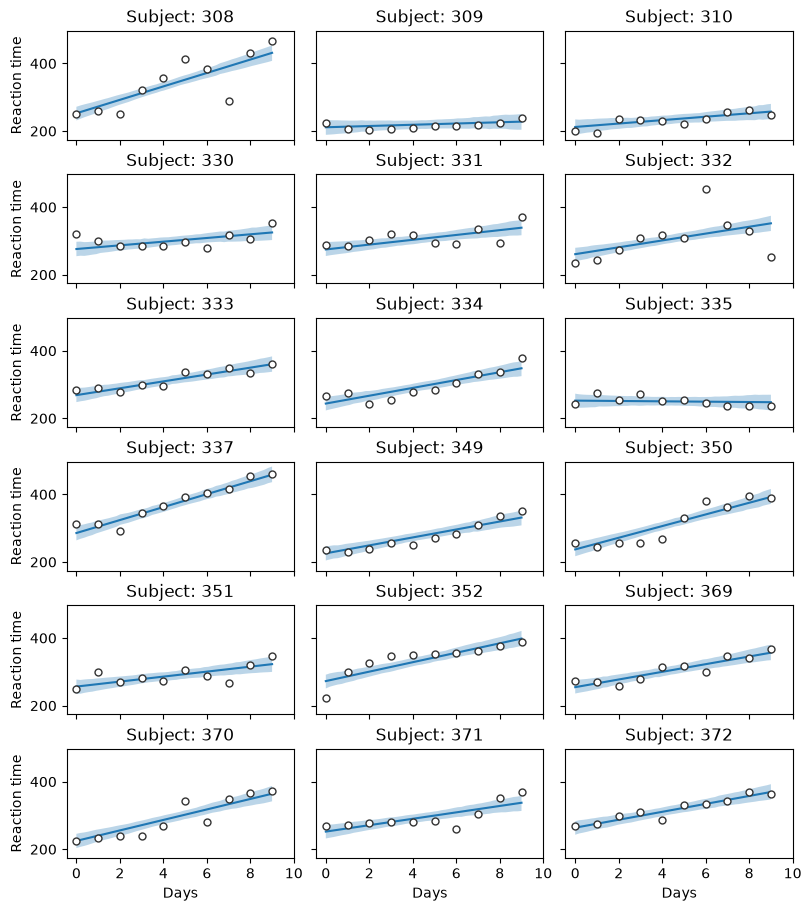

In [4]:
fig = plt.figure(figsize=(8, 9))
bmb.interpret.plot_predictions(
    model,
    idata,
    conditional=["Days", "Subject"],
    subplot_kwargs={"main": "Days", "panel": "Subject"},
    fig_kwargs={
        "ylabel": "Reaction time",
        "title": "Subject: {}".format,
        "wrap": 3,
        "theme": dict(plt.rcParams),
    },
).layout(engine="constrained").on(fig).plot()

for ax, subject in zip(fig.get_axes(), data["Subject"].unique()):
    ax.scatter(
        data.loc[data["Subject"] == subject, "Days"].to_numpy(),
        data.loc[data["Subject"] == subject, "Reaction"].to_numpy(),
        color="white",
        ec="0.2",
        s=25,
        zorder=10,
    )
    ax.set(xticks=[0, 2, 4, 6, 8, 10])

## Distribution of adoption times

An exponential survival model estimates mean adoption times for black cats and other cats. Adoptions are observed events; other outcomes are right-censored. The histograms show the posterior distributions of the mean times, rather than individual cats' waiting times.

The [AustinCats data](https://github.com/rmcelreath/rethinking/blob/master/data/AustinCats.csv) are distributed with Statistical Rethinking.

In [5]:
cats = pd.read_csv("data/AustinCats.csv.gz", sep=";")
cats["months"] = cats["days_to_event"] / 31
cats["status"] = np.where(cats["out_event"] == "Adoption", "none", "right")
cats["coat"] = np.where(cats["color"] == "Black", "Black cats", "Other cats")

cat_model = bmb.Model(
    "censored(months, status) ~ 0 + coat",
    cats,
    family="exponential",
    link="log",
    categorical="coat",
    priors={"coat": bmb.Prior("Normal", mu=0, sigma=1)},
)

cat_idata = cat_model.fit(random_seed=1305, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [coat]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 13 seconds.


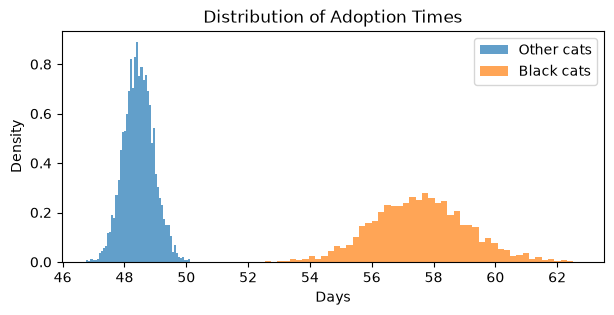

In [6]:
cat_model.predict(cat_idata, data=pd.DataFrame({"coat": ["Other cats", "Black cats"]}))
adoption_times = cat_idata.posterior["mu"] * 31

fig, ax = plt.subplots(figsize=(7, 3))
for index, label in enumerate(["Other cats", "Black cats"]):
    ax.hist(
        adoption_times.isel(__obs__=index).values.ravel(),
        bins=50,
        density=True,
        alpha=0.7,
        label=label,
    )
ax.set(xlabel="Days", ylabel="Density", title="Distribution of Adoption Times")
ax.legend();